<a href="https://colab.research.google.com/github/eshaans1305/AI-LAB/blob/main/lab7/Forward_Chaining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

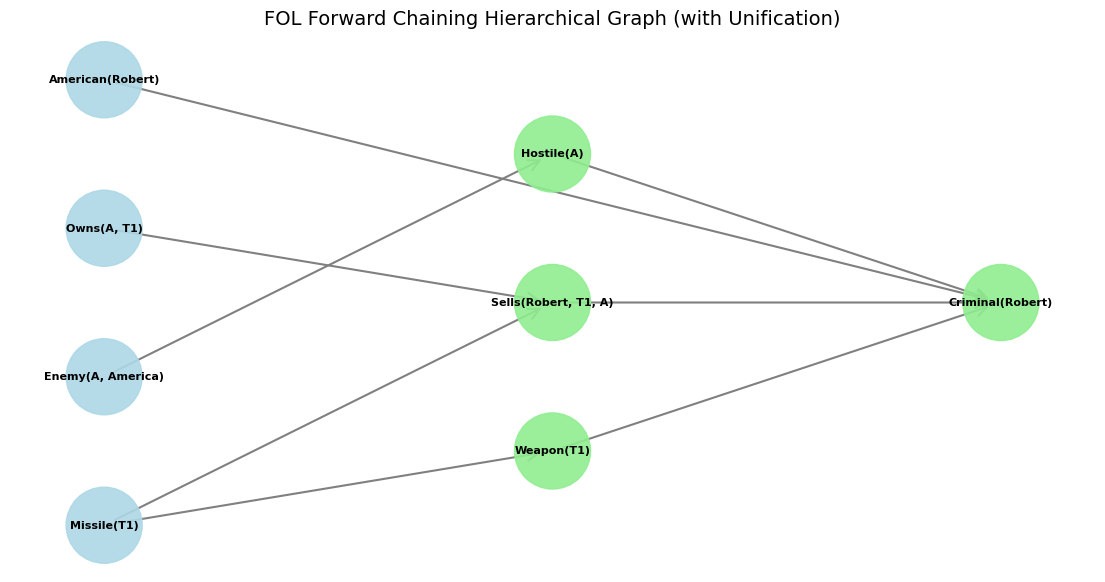

In [5]:
import matplotlib.pyplot as plt
import networkx as nx
import re


def parse_literal(literal_str):
    match = re.match(r"(\w+)\((.*)\)", literal_str.strip())
    if not match:
        return None
    pred = match.group(1)
    args = [arg.strip() for arg in match.group(2).split(",")]
    return {"pred": pred, "args": args}


def is_variable(x):
    return isinstance(x, str) and x.islower() and len(x) == 1


def unify(x, y, theta=None):
    if theta is None:
        theta = {}

    if theta is False:
        return False
    elif x == y:
        return theta
    elif is_variable(x):
        return unify_var(x, y, theta)
    elif is_variable(y):
        return unify_var(y, x, theta)
    elif isinstance(x, dict) and isinstance(y, dict):
        if x["pred"] != y["pred"] or len(x["args"]) != len(y["args"]):
            return False
        return unify(x["args"], y["args"], theta)
    elif isinstance(x, list) and isinstance(y, list):
        if len(x) != len(y):
            return False
        if not x:
            return theta
        return unify(x[1:], y[1:], unify(x[0], y[0], theta))
    else:
        return False


def unify_var(var, x, theta):
    if var in theta:
        return unify(theta[var], x, theta)
    elif x in theta:
        return unify(var, theta[x], theta)
    else:
        theta[var] = x
        return theta


def subst(theta, literal):
    parsed = parse_literal(literal) if isinstance(literal, str) else literal
    if not parsed:
        return literal

    new_args = []
    for arg in parsed["args"]:
        while is_variable(arg) and arg in theta:
            arg = theta[arg]
        new_args.append(arg)

    return f"{parsed['pred']}({', '.join(new_args)})"


class FOL_FC_Reasoner:

    def __init__(self):
        self.facts = set()
        self.rules = []
        self.graph = nx.DiGraph()

    def add_fact(self, fact):
        self.facts.add(fact)
        self.graph.add_node(fact, type="fact", color="lightblue", layer=0)

    def add_rule(self, premises, conclusion):
        self.rules.append((premises, conclusion))

    def fol_fc_ask(self, alpha):
        if alpha in self.facts:
            return True

        while True:
            new = set()

            for premises, q in self.rules:
                matches = [{}]

                for p_rule in premises:
                    parsed_p_rule = parse_literal(p_rule)
                    next_matches = []

                    for theta in matches:
                        subst_p_rule = parse_literal(
                            subst(theta, parsed_p_rule)
                        )

                        for fact in self.facts:
                            parsed_fact = parse_literal(fact)
                            t = unify(subst_p_rule, parsed_fact, theta.copy())
                            if t is not False:
                                next_matches.append(t)

                    matches = next_matches

                for theta in matches:
                    q_prime = subst(theta, q)

                    if q_prime not in self.facts and q_prime not in new:
                        new.add(q_prime)

                        actual_premises = [subst(theta, p) for p in premises]
                        premise_layers = [
                            self.graph.nodes[p].get("layer", 0)
                            for p in actual_premises
                        ]
                        q_layer = (
                            max(premise_layers) + 1 if premise_layers else 1
                        )

                        self.graph.add_node(
                            q_prime,
                            type="derived",
                            color="lightgreen",
                            layer=q_layer,
                        )
                        for p in actual_premises:
                            self.graph.add_edge(p, q_prime)

                        if q_prime == alpha:
                            self.facts.update(new)
                            return True

            if not new:
                break

            self.facts.update(new)

        return False

    def plot_graph(self):
        if not self.graph.nodes:
            return

        plt.figure(figsize=(14, 7))

        colors = [
            self.graph.nodes[node].get("color", "orange")
            for node in self.graph.nodes
        ]

        pos = nx.multipartite_layout(self.graph, subset_key="layer")

        nx.draw_networkx_nodes(
            self.graph, pos, node_color=colors, node_size=3000, alpha=0.9
        )
        nx.draw_networkx_edges(
            self.graph,
            pos,
            arrowstyle="->",
            arrowsize=20,
            edge_color="gray",
            width=1.5,
        )
        nx.draw_networkx_labels(
            self.graph, pos, font_size=8, font_weight="bold"
        )

        plt.title(
            "FOL Forward Chaining Hierarchical Graph (with Unification)",
            fontsize=14,
        )
        plt.axis("off")
        plt.show()


reasoner = FOL_FC_Reasoner()

reasoner.add_fact("Owns(A, T1)")
reasoner.add_fact("Missile(T1)")
reasoner.add_fact("American(Robert)")
reasoner.add_fact("Enemy(A, America)")

reasoner.add_rule(
    ["American(p)", "Weapon(q)", "Sells(p, q, r)", "Hostile(r)"], "Criminal(p)"
)
reasoner.add_rule(["Missile(x)"], "Weapon(x)")
reasoner.add_rule(["Enemy(x, America)"], "Hostile(x)")
reasoner.add_rule(["Missile(x)", "Owns(y, x)"], "Sells(Robert, x, y)")

goal = "Criminal(Robert)"

success = reasoner.fol_fc_ask(goal)
reasoner.plot_graph()
